# DecisionLab 01 — Comité d’investissement

**Janvier 2021, convention pédagogique.** Vous décidez d’expositions notionnelles à douze marchés immobiliers. Vos données sont de vrais indices Zillow Research, révisés à la date du téléchargement. Il ne s’agit ni de transactions individuelles, ni d’une reconstitution des données connues à l’époque.

**QUID** : où engager du capital sur six mois, avec quels coûts et quel risque ? Une ligne = une métropole et un mois. Indicateur = variation ZHVI à six mois, puis profit simulé. Décision = zones, allocations ou cash.

Ce kit fonctionne hors ligne après installation. Les données de révélation sont détenues séparément par l’enseignant. Ne cherchez pas les résultats historiques sur Internet pendant l’expérience.

Durée du notebook : 65 minutes guidées. **Le code de départ fonctionne sans remplir les TODO** ; ceux-ci demandent d’expliquer, choisir et comparer.

In [ ]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.json").exists() and (p / "src/modeling.py").exists())
sys.path.insert(0, str(ROOT))
from src.config import load_config
from src.validation import validate_panel
from src.modeling import features, split_training, validation_scores, decision_predictions, fit_predict
from src.decisions import select_allocations, export_strategy
from src.simulation import simulate
C = load_config()
PUBLIC = ROOT / "data/processed/history_public.csv"
panel = validate_panel(pd.read_csv(PUBLIC, parse_dates=["date"]))
assert panel.date.max() <= pd.Timestamp(C["public_cutoff"])
#modified
print(panel[['region_id', 'region']].drop_duplicates())
display(panel.head())

     region_id             region
0       394347        Atlanta, GA
72      394404         Boston, MA
144     394463        Chicago, IL
216     394514         Dallas, TX
288     394530         Denver, CO
360     394856          Miami, FL
432     394913       New York, NY
504     394976        Phoenix, AZ
576     395057  San Francisco, CA
648     395078        Seattle, WA
720     395148          Tampa, FL
792     753899    Los Angeles, CA


,region_id,region,date,zhvi
0,394347,"Atlanta, GA",2015-01-31,173942.955176
1,394347,"Atlanta, GA",2015-02-28,174853.818071
2,394347,"Atlanta, GA",2015-03-31,175804.313324
3,394347,"Atlanta, GA",2015-04-30,176865.134295
4,394347,"Atlanta, GA",2015-05-31,178034.638577


**Selon les caracterisque du jeu de données :** 
- la table 864 lignes et 4 colonnes
- 12 metropoles suivies qui correspondent au zones immobiliéres
- les données couvrents 6 ans d'observation mensuelles

## 1. Explorer — 8 min
Tracer trois séries. Vérifier unités, date maximale, nombre de zones et valeurs manquantes.

**TODO** : choisir trois zones ; expliquer pourquoi l’indice ne décrit pas le prix de chaque maison. Attribution : **Data Provided by Zillow Group**.

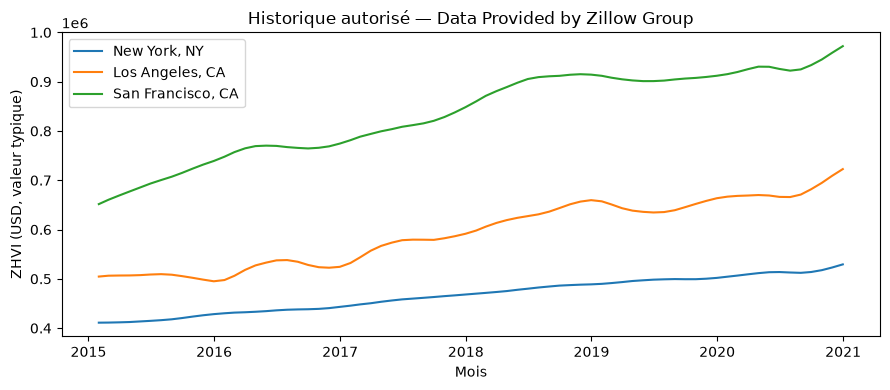

Valeurs absentes : {'region_id': 0, 'region': 0, 'date': 0, 'zhvi': 0}


In [4]:
zones = ["New York, NY", "Los Angeles, CA", "San Francisco, CA"] #modified 
fig, ax = plt.subplots(figsize=(9, 4))
for name in zones:
    part = panel[panel.region.eq(name)]
    ax.plot(part.date, part.zhvi, label=name)
ax.set(xlabel="Mois", ylabel="ZHVI (USD, valeur typique)", title="Historique autorisé — Data Provided by Zillow Group")
ax.legend()
plt.tight_layout()
plt.show()
print("Valeurs absentes :", panel.isna().sum().to_dict())

**Reponses** 
- zones choisies = NY, CA et SF 
- pourquoi l'indice ne décrit pas le prix de chaque maison : car l'indice ZHVI est un indicateur agrégé qui reflète la valeur médiane des maisons dans une région donnée, et ne prend pas en compte les variations individuelles des prix des maisons spécifiques.

## 2. Définir la cible et purger le train — 10 min

`target_pp = 100 × (ZHVI[t+6] / ZHVI[t] − 1)`. Une erreur de 2 signifie **2 points de pourcentage**, pas 2 dollars. Les entrées sont les variations passées à 1, 3, 6 et 12 mois.

Le train ne contient que des cibles entièrement réalisées **avant la première date de validation**. Les dernières lignes sans cible sont conservées pour la décision, jamais utilisées comme labels.

Convention de disponibilité : un mois de délai de publication, non vérifié pour chaque ancienne livraison. Même avec la purge, la série actuelle a été révisée ; ce n’est pas un backtest en données réellement archivées.

**TODO** : expliquer le risque d’un split aléatoire et lire les bornes affichées.

In [5]:
table = features(panel, C["horizon_months"])
train, valid = split_training(table, C)
assert train.target_end.max() < valid.date.min()
print("TRAIN", train.date.min(), train.date.max(), "fin des labels :", train.target_end.max())
print("VALIDATION", valid.date.min(), valid.date.max(), "fin des labels :", valid.target_end.max())
print("Effectifs", len(train), len(valid))
display(table[["region", "date", "return_6m_pp", "target_pp", "target_end"]].head(16))

TRAIN 2016-01-31 00:00:00 2018-06-30 00:00:00 fin des labels : 2018-12-31 00:00:00
VALIDATION 2019-01-31 00:00:00 2019-12-31 00:00:00 fin des labels : 2020-06-30 00:00:00
Effectifs 360 144


,region,date,return_6m_pp,target_pp,target_end
0,"Atlanta, GA",2015-01-31,NaN,3.724157,2015-07-31
1,"Atlanta, GA",2015-02-28,NaN,3.900665,2015-08-31
2,"Atlanta, GA",2015-03-31,NaN,4.102620,2015-09-30
3,"Atlanta, GA",2015-04-30,NaN,4.203907,2015-10-31
4,"Atlanta, GA",2015-05-31,NaN,4.223333,2015-11-30
5,"Atlanta, GA",2015-06-30,NaN,4.304432,2015-12-31
6,"Atlanta, GA",2015-07-31,3.724157,4.415817,2016-01-31
7,"Atlanta, GA",2015-08-31,3.900665,4.528959,2016-02-29
8,"Atlanta, GA",2015-09-30,4.102620,4.427097,2016-03-31
9,"Atlanta, GA",2015-10-31,4.203907,4.374915,2016-04-30


**Reponses**
- risque d’un split aléatoire : le risque est que les données de train et de test ne soient pas représentatives de la distribution réelle des données, ce qui peut entraîner un modèle biaisé ou surajusté. Un découpage aléatoire mélange les dates et crée des fuites de données temporelles (data leakage). Le modèle s'entraînerait avec des données du futur qu'il n'est pas censé connaître au moment d'apprendre ou de décider..

- bornes affichées :
Train : Du 2015-01-31 au 2018-06-30 (fin des cibles : 2018-12-31), Validation : Du 2019-01-31 au 2019-12-31 (fin des cibles : 2020-06-30)
Donc les bornes affichées représentent les limites de la période de temps utilisée pour l'entraînement et la validation du modèle. Elles permettent de s'assurer que le modèle est évalué sur des données qui n'ont pas été utilisées pour l'entraînement, garantissant ainsi une évaluation plus réaliste de sa performance.


## 3. Baselines et régression — 12 min

Comparer « variation nulle », « dernière variation à six mois » et régression linéaire. Le prétraitement est appris uniquement sur le train.

**TODO** : choisir une méthode sur la validation ; justifier en MAE, RMSE et biais. Aucun score de test futur n’est fourni ici.

In [6]:
scores = validation_scores(table, C)
display(scores.round(3))
MODEL = "linear"  # TODO : choix = linear 
predictions = decision_predictions(panel, MODEL, C)
display(predictions.round(3))

,model,observations,mae_pp,rmse_pp,bias_pp
0,zero,144,2.237,2.617,-2.140
1,momentum,144,1.717,2.264,-0.757
2,linear,144,1.276,1.566,0.719


C:\Users\taleb\AppData\Local\Temp\ipykernel_13456\1520140911.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(predictions.round(3))


,region_id,region,date,zhvi,predicted_return_pp
0,394347,"Atlanta, GA",2020-12-31,274874.204,4.047
1,394404,"Boston, MA",2020-12-31,537209.556,3.649
2,394463,"Chicago, IL",2020-12-31,254993.343,2.923
3,394514,"Dallas, TX",2020-12-31,280431.352,3.570
4,394530,"Denver, CO",2020-12-31,466143.645,3.166
5,394856,"Miami, FL",2020-12-31,325594.553,3.544
6,394913,"New York, NY",2020-12-31,529334.502,3.496
7,394976,"Phoenix, AZ",2020-12-31,338724.550,4.525
8,395057,"San Francisco, CA",2020-12-31,972106.334,3.002
9,395078,"Seattle, WA",2020-12-31,570616.640,3.719


**Reponses**
- Méthode choisie : MODEL = "linear".   Pourquoi: Il offre le meilleur compromis entre précision et régularité, réduisant l'erreur moyenne de plus de 25 % par rapport aux baselines tout en conservant une grande simplicité d'interprétation.
- MAE (Erreur Absolue Moyenne) : C'est le modèle le plus précis avec seulement 1,28 point de pourcentage d'erreur, contre 1,72 pour le momentum et 2,24 pour la baseline zéro.
- RMSE (Pénalité des fortes erreurs) : Il obtient la valeur la plus basse avec 1,57 point, ce qui prouve qu'il limite fortement les erreurs de prédiction fortes.
- Biais : Le biais positif reste modéré (+0,72 point), évitant la sous-estimation marquée des autres approches

## 4. Passer de la prévision à la décision — 15 min

Hypothèses **simulées**, communes à la séance : budget, frais d’achat, frais de vente, portage, limite par zone et cash minimal. La marge de sécurité est un seuil de sélection, **pas un coût ajouté au profit**.

Le code choisit des zones uniquement si leur rendement net prévu dépasse la marge. Il peut ne rien acheter. Les coûts de rénovation et les financements propres à Zillow ne sont pas reconstitués.

**TODO** : tester une marge différente sur la validation, puis fixer la vôtre. Comparer aussi à conserver du cash. Les contraintes communes ne changent pas entre groupes.

In [17]:
economics = dict(C["economics"])
economics["safety_margin_pp"] = C["economics"]["safety_margin_pp"] = 0.2  # TODO : marge en points
TOP_N = 5
# Validation économique sur douze cohortes mensuelles séparées, budget réinitialisé par cohorte.
# Ces cohortes se chevauchent : ce n’est PAS un portefeuille cumulé ni 12 expériences indépendantes.
validation_economics = []
for origin, cohort in valid.groupby("date"):
    cohort = cohort.copy()
    cohort["predicted_return_pp"] = fit_predict(train, cohort, MODEL, C["horizon_months"])
    positions = select_allocations(cohort, economics, C["horizon_months"], TOP_N)
    actual = cohort[["region_id", "target_pp"]].rename(columns={"target_pp": "actual_return_pp"})
    result, _ = simulate(positions, actual, economics, C["horizon_months"])
    validation_economics.append({"origin": origin, **result})
validation_economics = pd.DataFrame(validation_economics)
display(validation_economics[["origin", "capital_engaged_usd", "profit_usd", "return_on_budget_pct"]].round(2))
#modified
predictions = table[table["date"] == table["date"].max()].copy()
predictions["predicted_return_pp"] = fit_predict(train, predictions, MODEL, C["horizon_months"])

allocations = select_allocations(predictions, economics, C["horizon_months"], TOP_N)
display(pd.DataFrame(allocations, columns=["region_id", "capital_usd"]))
print("Cash volontaire possible. Aucune réalisation future consultée.")

C:\Users\taleb\AppData\Local\Temp\ipykernel_13456\2025407320.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(validation_economics[["origin", "capital_engaged_usd", "profit_usd", "return_on_budget_pct"]].round(2))


,origin,capital_engaged_usd,profit_usd,return_on_budget_pct
0,2019-01-31,0.0,0.00,0.00
1,2019-02-28,0.0,0.00,0.00
2,2019-03-31,0.0,0.00,0.00
3,2019-04-30,2000000.0,-38105.38,-0.38
4,2019-05-31,2000000.0,-11672.40,-0.12
5,2019-06-30,0.0,0.00,0.00
6,2019-07-31,0.0,0.00,0.00
7,2019-08-31,0.0,0.00,0.00
8,2019-09-30,0.0,0.00,0.00
9,2019-10-31,0.0,0.00,0.00


,region_id,capital_usd
0,394976,2000000.0


Cash volontaire possible. Aucune réalisation future consultée.


**Reponses**
J'ai commencer avec une marge a 0.5 point au-dessus des frais de transaction et de portage  Conséquence : aucun marché n'était retenu et la stratégie conservait 100 % en cash par prudence.
Donc je suis passée à 0,2 point :
En abaissant la marge, le filtre devient suffisamment accessible pour débloquer l'opportunité sur la meilleure zone (Phoenix, AZ — 394976).

Pour résumer, la marge initiale de 0,5 point s'est révélée trop restrictive en bloquant tout réinvestissement à cause de la couverture des frais. Régler la marge à 0,2 point permet de sélectionner le marché le plus performant tout en maintenant un critère de rentabilité positive net de tous coûts.

- Capital engagé : 2 000 000 $ alloués sur la zone 394976 (Phoenix, AZ).

- Conservation de cash : 80 % du budget reste conservé en cash pour éviter d'exposer le portefeuille à des métropoles dont les gains prévus seraient absorbés par les frais de transaction et de portage.


## 5. Geler la stratégie — 8 min

Changer `TEAM` pour votre groupe, vérifier les positions, puis exécuter l’export **une seule fois**. Les fichiers existants ne sont pas remplacés. Remettre le JSON et son empreinte à l’enseignant avant révélation.

**TODO** : dans un fichier `pitch.txt`, écrire la méthode, le motif de la marge et du niveau de cash, un risque et un signal d’arrêt.

L’empreinte détecte les modifications ; seule la collecte externe par l’enseignant établit l’engagement avant révélation.

In [18]:
TEAM = "morgiane"  # TODO : Groupe_1, Groupe_2, Groupe_3 ou Groupe_4
path, sha256 = export_strategy(TEAM, MODEL, allocations, economics, PUBLIC, ROOT / "submissions", C)
print("Fichier à remettre :", path)
print("SHA256 :", sha256)

import json

submission_data = {
    "model": MODEL,
    "safety_margin_pp": economics["safety_margin_pp"],
    "allocations": allocations
}

with open("submission.json", "w") as f:
    json.dump(submission_data, f, indent=4)

print("Fichier submission.json généré avec succès !")

Fichier à remettre : c:\Users\taleb\OneDrive - EduServices\Bureau\python\ai-course-student\usecase\DecisionLab_01_Zillow_Etudiant\submissions\morgiane.json
SHA256 : 9c23bedff8d0adc9296e4ceae195cd04f57311d23b34f80f74676dff839dd2be
Fichier submission.json généré avec succès !


## 6. Préparer le conseil d’administration — 12 min

Sans consulter de futur, préparer un pitch de deux minutes :
1. Quelle méthode et quelle erreur de validation ?
2. Combien investir et pourquoi garder du cash ?
3. Quel risque les indices ne représentent-ils pas ?
4. Qu’est-ce qui pourrait invalider votre décision ?

L’enseignant révélera ensuite les indices futurs et fera tourner le moteur privé. Vous interpréterez le profit, les pertes, l’exposition, les scénarios de stress et la différence avec les stratégies naïves. Une bonne MAE ne garantit ni profit ni robustesse.

**PITCH** 

**Méthode et Erreur de validation** 
- Modèle retenu : Régression linéaire (MODEL = "linear").
- Métriques : MAE de 1,28 point de pourcentage (et RMSE de 1,57 point).
- Atout : Réduit l'erreur de plus de 25 % par rapport au momentum et évite les gros écarts de prédiction.

**Allocation et Cash**
- Investissement : 2 000 000 $ alloués sur Phoenix, AZ (394976).
- Cash conservé : 8 000 000 $ (80 %).
- Raison : La marge de sécurité à 0,2 point sélectionne uniquement le marché le plus solide. Le cash protège le capital des zones dont le rendement net serait mangé par les frais.

**Risque non vu par les indices**
Limite de la MAE : Elle mesure une précision mathématique passive, mais ignore :
- Les frais réels : achat, vente, portage,
- Le risque de liquidité : impossibilité de revendre rapidement au prix du marché,
- L'asymétrie des pertes : une surestimation coûte de l'argent réel, pas une sous-estimation.

**Facteurs d'invalidation**
- Choc macroéconomique : Remontée des taux faisant chuter les prix sous nos prévisions.
- Hausse des frais : Des coûts de portage supérieurs à nos +0,2 point de marge.
- Retournement local : Enrayement de la dynamique immobilière spécifique à Phoenix.